# Digital Image Processing — Week 5 · Task 3

**Grup: Nmertgules ve Iliya**

Renkli görüntüyü OpenCV ve kendi fonksiyonumuzla tek kanallı griye dönüştürüp aynı konumdaki pikselleri karşılaştırıyoruz.

Formül: **Y = 0.299R + 0.587G + 0.114B**. OpenCV girdisi BGR sırasındadır. Kendi fonksiyonumuz ağırlıklı toplamı hesaplar, en yakın tam sayıya yuvarlar ve uint8'e dönüştürür. Hazır renk dönüşümü kullanmaz. OpenCV'nin tamsayı yaklaşımı/yuvarlaması nedeniyle bir gri seviye fark oluşabilir; sonuçları ölçerek raporluyoruz.


In [1]:
from pathlib import Path
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

HERE = Path('week5') if Path('week5').is_dir() else Path('.')
IMAGE = HERE.parent / 'week4' / 'assets' / 'rocket.jpg'
bgr = cv2.imread(str(IMAGE), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f'Görüntü okunamadı: {IMAGE}. Repoyu bütünüyle indirin.')
OUT = HERE / 'results'
OUT.mkdir(exist_ok=True)
print('OpenCV:', cv2.__version__, '| NumPy:', np.__version__)
print('Görüntü:', bgr.shape)


OpenCV: 5.0.0 | NumPy: 2.5.4
Görüntü: (427, 640, 3)


In [2]:
def bgr_to_gray_manual(image):
    """uint8 BGR görüntüyü ağırlıklı toplamla tek kanallı griye dönüştür."""
    if image.ndim != 3 or image.shape[2] != 3 or image.dtype != np.uint8:
        raise ValueError('Üç kanallı uint8 BGR görüntü bekleniyor.')
    # Önce float64: uint8 aritmetiğinde taşmayı engeller.
    b = image[:, :, 0].astype(np.float64)
    g = image[:, :, 1].astype(np.float64)
    r = image[:, :, 2].astype(np.float64)
    weighted = (114 * b + 587 * g + 299 * r) / 1000.0
    return np.clip(np.floor(weighted + 0.5), 0, 255).astype(np.uint8)

gray_cv = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_manual = bgr_to_gray_manual(bgr)
assert gray_manual.ndim == 2 and gray_manual.dtype == np.uint8
assert gray_manual.shape == gray_cv.shape


In [3]:
# uint8 ile doğrudan çıkarma taşar; önce işaretli tipe dönüştürüyoruz.
difference = np.abs(gray_cv.astype(np.int16) - gray_manual.astype(np.int16))
metrics = {
    'width': int(bgr.shape[1]), 'height': int(bgr.shape[0]),
    'total_pixels': int(difference.size),
    'different_pixels': int(np.count_nonzero(difference)),
    'different_percent': float(100 * np.count_nonzero(difference) / difference.size),
    'max_absolute_difference': int(difference.max()),
    'mean_absolute_difference': float(difference.mean()),
    'rmse': float(np.sqrt(np.mean(difference.astype(np.float64) ** 2))),
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))
(OUT / 'task3_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
# Her pikselin gerçek farkı dosyada; görüntüleme için büyütülmemiştir.
cv2.imwrite(str(OUT / 'task3_opencv_gray.png'), gray_cv)
cv2.imwrite(str(OUT / 'task3_manual_gray.png'), gray_manual)
cv2.imwrite(str(OUT / 'task3_absolute_difference.png'), difference.astype(np.uint8))
assert difference.max() <= 1, 'Beklenenden büyük dönüşüm farkı'


{
  "width": 640,
  "height": 427,
  "total_pixels": 273280,
  "different_pixels": 1,
  "different_percent": 0.0003659250585480094,
  "max_absolute_difference": 1,
  "mean_absolute_difference": 3.6592505854800937e-06,
  "rmse": 0.0019129167743213748
}


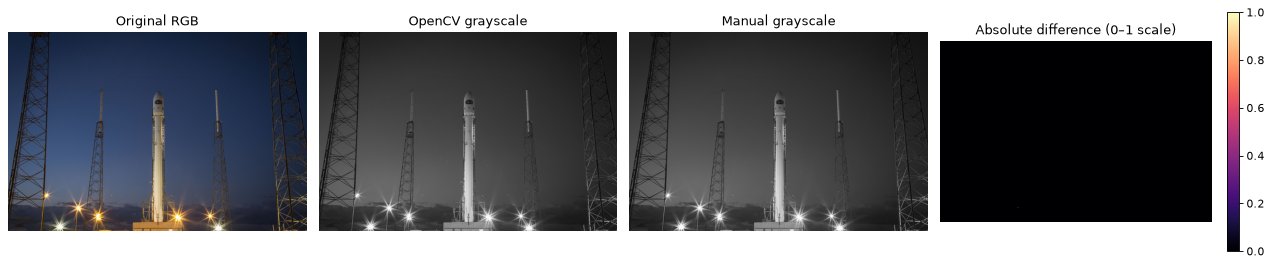

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title('Original RGB')
axes[1].imshow(gray_cv, cmap='gray', vmin=0, vmax=255); axes[1].set_title('OpenCV grayscale')
axes[2].imshow(gray_manual, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Manual grayscale')
im = axes[3].imshow(difference, cmap='magma', vmin=0, vmax=max(1, int(difference.max())))
axes[3].set_title('Absolute difference (0–1 scale)')
fig.colorbar(im, ax=axes[3], fraction=0.04)
for ax in axes: ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'task3_comparison.png', dpi=110)
plt.show()


In [5]:
# BGR sırası ve katsayılar: siyah, beyaz, saf mavi, yeşil, kırmızı.
known = np.array([[[0,0,0], [255,255,255], [255,0,0], [0,255,0], [0,0,255]]], dtype=np.uint8)
assert np.array_equal(bgr_to_gray_manual(known), np.array([[0,255,29,150,76]], dtype=np.uint8))
# Tüm nötr griler değişmeden kalmalı.
neutral = np.repeat(np.arange(256, dtype=np.uint8)[None, :, None], 3, axis=2)
assert np.array_equal(bgr_to_gray_manual(neutral), neutral[:,:,0])
rng = np.random.default_rng(42)
random_image = rng.integers(0, 256, (127, 193, 3), dtype=np.uint8)
random_diff = np.abs(cv2.cvtColor(random_image, cv2.COLOR_BGR2GRAY).astype(np.int16)
                     - bgr_to_gray_manual(random_image).astype(np.int16))
assert random_diff.max() <= 1
print('Bilinen renkler, 256 nötr gri ve rastgele görüntü kontrolleri geçti.')
print('Rastgele görüntü maksimum farkı:', int(random_diff.max()))


Bilinen renkler, 256 nötr gri ve rastgele görüntü kontrolleri geçti.
Rastgele görüntü maksimum farkı: 1
